# Aurisign FIlipino Sign Language Gesture Recognition 1D CNN Alphabets Training

## Dependency Installation and Imports

In [1]:
!pip install opencv-python mediapipe==0.10.14 matplotlib seaborn tensorflow scikit-learn tensorflowjs


[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [2]:
# %%
import cv2
import mediapipe as mp
import numpy as np
import os
from time import time

2026-10-11 22:24:36.902121: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-11 22:24:36.998741: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-11 22:24:37.095295: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1791728677.171630    9610 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1791728677.194227    9610 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1791728677.361178    9610 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linkin

### Data Collection

In [5]:
# %%
# Record 24-frame sequences for each supported class and diverse unsupported gestures for NONE.
# For NONE, vary poses, movement, backgrounds, and people; do not record a supported sign as NONE.
# Press "c" to record one full sequence for the current letter, "q" to move to the next letter.
MOTION_CLASSES = ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J", "K", "L", "M", "N", "Ñ", "Ng", "O", "P", "Q", "R", "S", "T", "U", "V", "W", "X", "Y", "Z", "NONE"]   # full set — used everywhere downstream

MOTION_DATA_PATH = "alphabet_dataset"
SEQ_LEN = 24                 # ~0.8-1s of motion at a typical webcam framerate
ADDITIONAL_SAMPLES_PER_GESTURE = 200  # keeps existing files and records this many more
CENTER_BY_WRIST = True
INCLUDE_HANDEDNESS = True
NUM_FEATURES = 64 if INCLUDE_HANDEDNESS else 63

os.makedirs(MOTION_DATA_PATH, exist_ok=True)
for g in MOTION_CLASSES:
    os.makedirs(os.path.join(MOTION_DATA_PATH, g), exist_ok=True)

mp_hands = mp.solutions.hands
mp_draw  = mp.solutions.drawing_utils
hands = mp_hands.Hands(static_image_mode=False, max_num_hands=1,
                       min_detection_confidence=0.7, min_tracking_confidence=0.7)

cap = cv2.VideoCapture(0)

def get_frame_keypoints(frame):
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    result = hands.process(rgb)
    if not result.multi_hand_landmarks:
        return None, frame
    lm = result.multi_hand_landmarks[0]
    mp_draw.draw_landmarks(frame, lm, mp_hands.HAND_CONNECTIONS)
    pts = np.array([[p.x, p.y, p.z] for p in lm.landmark])
    if CENTER_BY_WRIST:
        pts -= pts[0]
    pts = pts.flatten()
    if INCLUDE_HANDEDNESS and result.multi_handedness:
        hl = result.multi_handedness[0].classification[0].label
        pts = np.append(pts, 0 if hl == "Left" else 1)
    return pts, frame

for gesture in MOTION_CLASSES:
    print(f"Collecting motion: {gesture} — [c]=record one {SEQ_LEN}-frame sequence, [q]=next letter")
    existing = [int(os.path.splitext(f)[0]) for f in os.listdir(os.path.join(MOTION_DATA_PATH, gesture))
                if f.endswith(".npy") and os.path.splitext(f)[0].isdigit()]
    count = max(existing, default=-1) + 1
    target = count + ADDITIONAL_SAMPLES_PER_GESTURE
    while count < target:
        ret, frame = cap.read()
        if not ret:
            continue
        frame = cv2.flip(frame, 1)
        _, frame = get_frame_keypoints(frame.copy())
        cv2.putText(frame, f"{gesture} {count}/{target}  [c]=record  [q]=next",
                    (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
        cv2.imshow("Collect Motion Gestures", frame)
        k = cv2.waitKey(1) & 0xFF

        if k == ord("c"):
            sequence = []
            print(f"  Recording {gesture} #{count}... perform the gesture now")
            while len(sequence) < SEQ_LEN:
                ret, f2 = cap.read()
                if not ret:
                    continue
                f2 = cv2.flip(f2, 1)
                kp, f2 = get_frame_keypoints(f2)
                # a short mid-gesture occlusion shouldn't corrupt the whole window,
                # so hold the last known keypoints instead of dropping the frame
                if kp is None and sequence:
                    kp = sequence[-1]
                elif kp is None:
                    kp = np.zeros(NUM_FEATURES)
                sequence.append(kp)
                cv2.putText(f2, f"RECORDING {len(sequence)}/{SEQ_LEN}", (10, 30),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
                cv2.imshow("Collect Motion Gestures", f2)
                cv2.waitKey(1)
            np.save(os.path.join(MOTION_DATA_PATH, gesture, f"{count:03d}.npy"), np.array(sequence))
            count += 1

        if k == ord("q"):
            break

cap.release()
cv2.destroyAllWindows()
print("Done collecting motion gestures!")

I0000 00:00:1791728781.867296    9610 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1791728781.869069   12606 gl_context.cc:357] GL version: 3.2 (OpenGL ES 3.2 Mesa 25.0.7-0ubuntu0.24.04.2), renderer: Mesa Intel(R) UHD Graphics 620 (WHL GT2)
W0000 00:00:1791728781.881447   12599 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791728781.901698   12596 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


  Recording NONE #0... perform the gesture now
  Recording NONE #1... perform the gesture now
  Recording NONE #2... perform the gesture now
  Recording NONE #3... perform the gesture now
  Recording NONE #4... perform the gesture now
  Recording NONE #5... perform the gesture now
  Recording NONE #6... perform the gesture now
  Recording NONE #7... perform the gesture now
  Recording NONE #8... perform the gesture now
  Recording NONE #9... perform the gesture now
  Recording NONE #10... perform the gesture now
  Recording NONE #11... perform the gesture now
  Recording NONE #12... perform the gesture now
  Recording NONE #13... perform the gesture now
  Recording NONE #14... perform the gesture now
  Recording NONE #15... perform the gesture now
  Recording NONE #16... perform the gesture now
  Recording NONE #17... perform the gesture now
  Recording NONE #18... perform the gesture now
  Recording NONE #19... perform the gesture now
  Recording NONE #20... perform the gesture now
  

### Alphabet Data Loading and Preprocessing

In [6]:
# Load saved 24-frame sequences; use stratification to preserve each class in both splits.
import tensorflow as tf
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split

X_motion, y_indices = [], []
for i, gesture in enumerate(MOTION_CLASSES):
    folder = os.path.join(MOTION_DATA_PATH, gesture)
    paths = sorted(f for f in os.listdir(folder) if f.lower().endswith('.npy'))
    if not paths:
        raise ValueError(f"No .npy samples for {gesture}. Record examples before training.")
    for f in paths:
        sample = np.load(os.path.join(folder, f), allow_pickle=False)
        if sample.shape != (SEQ_LEN, NUM_FEATURES) or not np.isfinite(sample).all():
            raise ValueError(f"Invalid sequence {gesture}/{f}: shape {sample.shape}")
        X_motion.append(sample)
        y_indices.append(i)

X_motion = np.asarray(X_motion, dtype=np.float32)
y_indices = np.asarray(y_indices, dtype=np.int64)
counts = np.bincount(y_indices, minlength=len(MOTION_CLASSES))
print('Samples per class:', dict(zip(MOTION_CLASSES, counts.tolist())))
if counts.min() < 3:
    raise ValueError('Collect at least 3 samples per class; preferably many more.')

# Separate held-out test data. Validation data comes ONLY from the training partition.
X_train_all, Xm_test, y_train_all, y_test_idx = train_test_split(
    X_motion, y_indices, test_size=0.20, random_state=42, stratify=y_indices)
Xm_train, Xm_val, y_train_idx, y_val_idx = train_test_split(
    X_train_all, y_train_all, test_size=0.20, random_state=42, stratify=y_train_all)
ym_train = to_categorical(y_train_idx, num_classes=len(MOTION_CLASSES))
ym_val = to_categorical(y_val_idx, num_classes=len(MOTION_CLASSES))
ym_test = to_categorical(y_test_idx, num_classes=len(MOTION_CLASSES))
print('Train:', Xm_train.shape, 'Validation:', Xm_val.shape, 'Test:', Xm_test.shape)
# IMPORTANT: If consecutive recordings are nearly identical, random splitting may inflate scores.
# For stronger evidence, hold out entire recording sessions or participants for final testing.


Samples per class: {'A': 200, 'B': 200, 'C': 200, 'D': 200, 'E': 200, 'F': 200, 'G': 200, 'H': 200, 'I': 200, 'J': 150, 'K': 200, 'L': 200, 'M': 200, 'N': 200, 'Ñ': 150, 'Ng': 150, 'O': 200, 'P': 200, 'Q': 200, 'R': 200, 'S': 200, 'T': 200, 'U': 200, 'V': 200, 'W': 200, 'X': 200, 'Y': 200, 'Z': 150, 'NONE': 200}
Train: (3584, 24, 64) Validation: (896, 24, 64) Test: (1120, 24, 64)


### Alphabet Model

In [7]:
# %%
motion_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(SEQ_LEN, X_motion.shape[-1])),
    tf.keras.layers.Conv1D(64, 3, activation='relu', padding='same'),
    tf.keras.layers.Conv1D(64, 3, activation='relu', padding='same'),
    tf.keras.layers.GlobalAveragePooling1D(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(len(MOTION_CLASSES), activation='softmax'),
])
motion_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
motion_model.summary()

2026-10-11 22:30:44.223776: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 24, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 24, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 29)             │         1,885 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,749 (120.11 KB)

 Trainable params: 30,749 (120.11 KB)

 Non-trainable params: 0 (0.00 B)

### Alphabet Model Training

In [8]:
# Validation is used for model selection; the test set is reserved for final evaluation.
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
]
motion_history = motion_model.fit(
    Xm_train, ym_train, validation_data=(Xm_val, ym_val),
    epochs=50, batch_size=8, callbacks=callbacks)


Epoch 1/50
448/448 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.2458 - loss: 2.4579 - val_accuracy: 0.5938 - val_loss: 1.3556
Epoch 2/50
448/448 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5834 - loss: 1.1873 - val_accuracy: 0.7801 - val_loss: 0.6481
Epoch 3/50
448/448 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7268 - loss: 0.7604 - val_accuracy: 0.8438 - val_loss: 0.4555
Epoch 4/50
448/448 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7944 - loss: 0.5699 - val_accuracy: 0.8973 - val_loss: 0.2996
Epoch 5/50
448/448 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8446 - loss: 0.4459 - val_accuracy: 0.8895 - val_loss: 0.2757
Epoch 6/50
448/448 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8610 - loss: 0.3716 - val_accuracy: 0.9107 - val_loss: 0.2271
Epoch 7/50
448/448 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8708 - loss: 0.3309 - val_accuracy: 0.9208 - val_loss: 0.1876
Epoch 8/50
448/448 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9037 - loss: 0.2761 - val_accuracy: 0.

### Held-out Evaluation: Confusion Matrix, Precision, Recall and F1


              precision    recall  f1-score   support

           A      1.000     1.000     1.000        40
           B      1.000     1.000     1.000        40
           C      1.000     1.000     1.000        40
           D      0.976     1.000     0.988        40
           E      0.976     1.000     0.988        40
           F      1.000     1.000     1.000        40
           G      0.976     1.000     0.988        40
           H      1.000     1.000     1.000        40
           I      1.000     1.000     1.000        40
           J      1.000     1.000     1.000        30
           K      1.000     1.000     1.000        40
           L      1.000     1.000     1.000        40
           M      0.975     0.975     0.975        40
           N      1.000     1.000     1.000        40
           Ñ      1.000     1.000     1.000        30
          Ng      1.000     0.967     0.983        30
           O      1.000     1.000     1.000        40
           P      1.000    

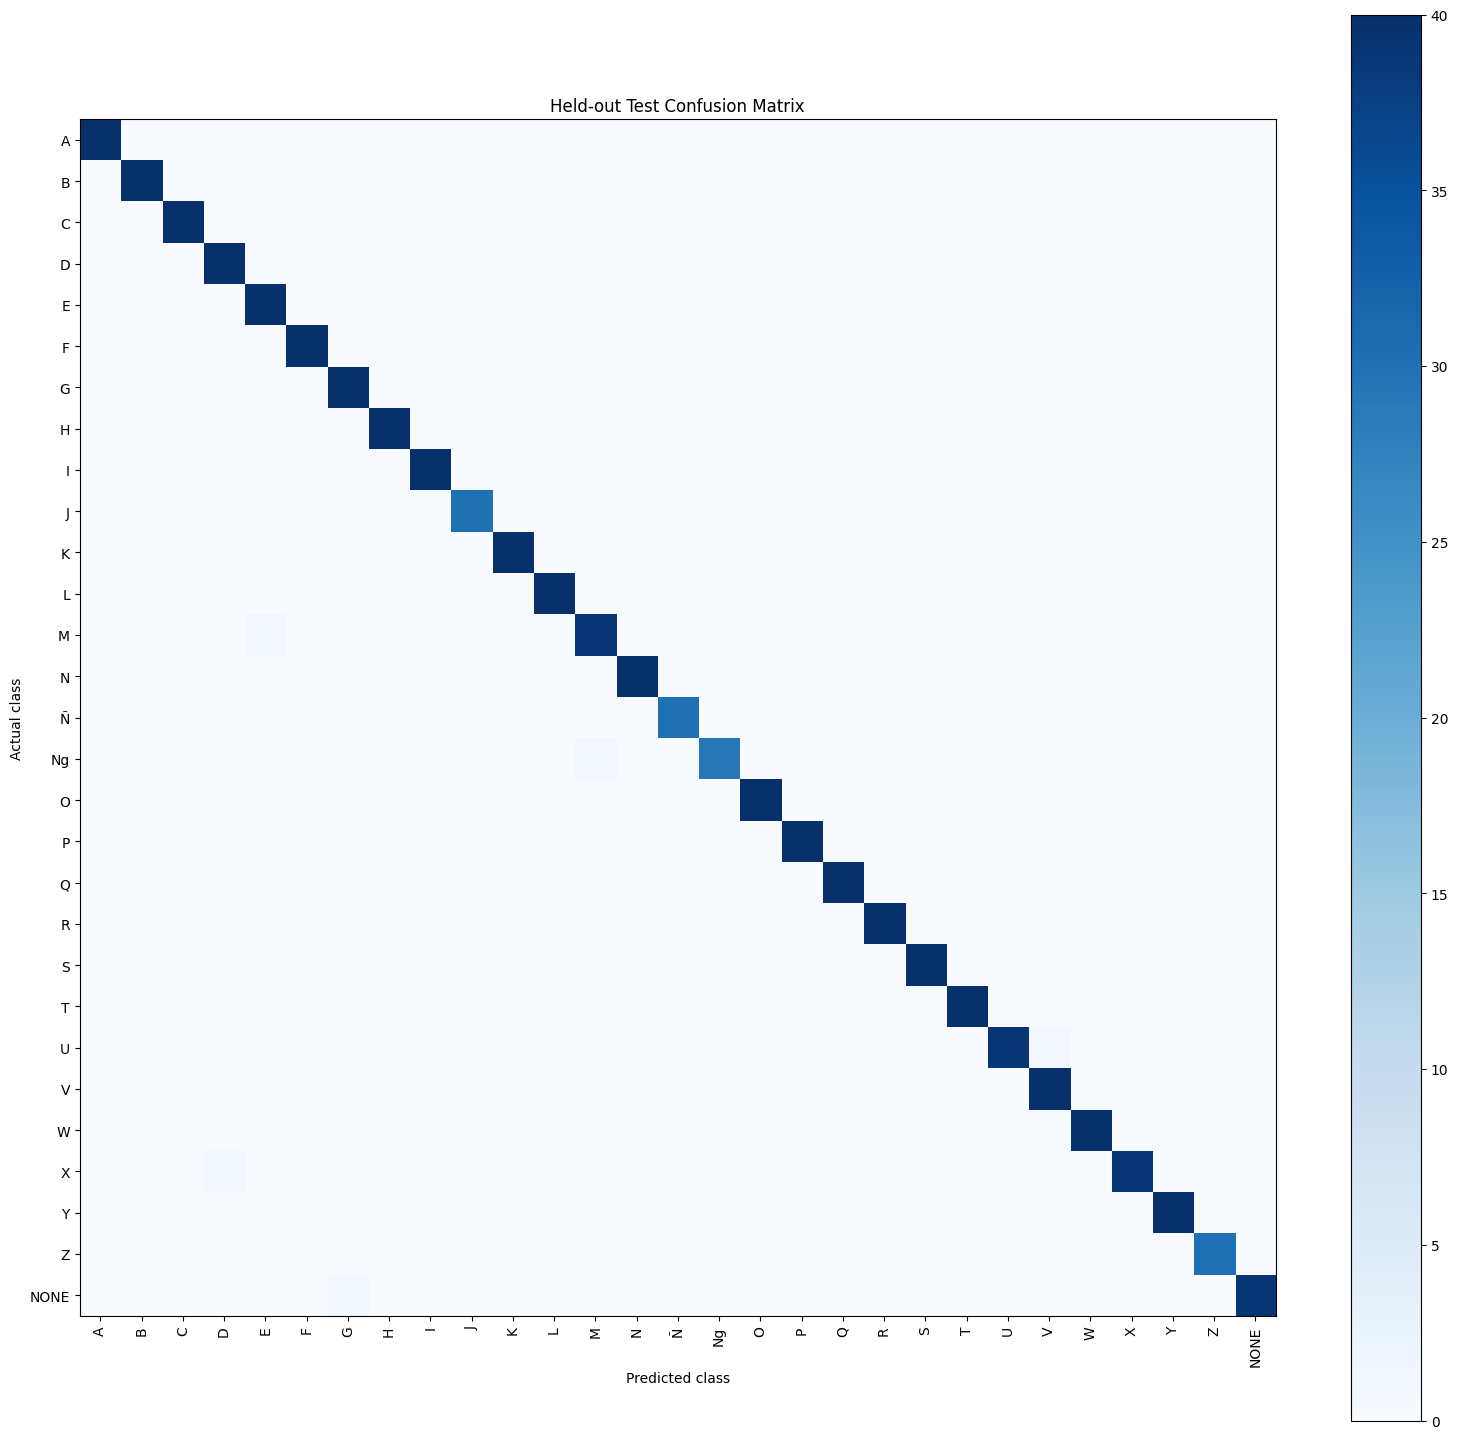

In [10]:
# Held-out test evaluation: confusion matrix, per-class precision/recall/F1, and macro/weighted scores.
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_fscore_support
import matplotlib.pyplot as plt

probabilities = motion_model.predict(Xm_test, verbose=0)
y_pred_idx = np.argmax(probabilities, axis=1)
print(classification_report(y_test_idx, y_pred_idx, labels=np.arange(len(MOTION_CLASSES)),
                            target_names=MOTION_CLASSES, digits=3, zero_division=0))
cm = confusion_matrix(y_test_idx, y_pred_idx, labels=np.arange(len(MOTION_CLASSES)))
fig, ax = plt.subplots(figsize=(max(10, len(MOTION_CLASSES)*0.55), max(8, len(MOTION_CLASSES)*0.5)))
image = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(len(MOTION_CLASSES)), MOTION_CLASSES, rotation=90)
ax.set_yticks(range(len(MOTION_CLASSES)), MOTION_CLASSES)
ax.set_xlabel('Predicted class'); ax.set_ylabel('Actual class')
ax.set_title('Held-out Test Confusion Matrix')
fig.colorbar(image, ax=ax)
if len(MOTION_CLASSES) <= 15:
    for row in range(len(MOTION_CLASSES)):
        for col in range(len(MOTION_CLASSES)):
            ax.text(col, row, str(cm[row, col]), ha='center', va='center', fontsize=8)
plt.tight_layout(); plt.show()


### Alphabet Model Export

In [11]:
# %%
motion_model.export("alphabet_model")
print("Alphabet SavedModel export complete!")

# In Google Colab, convert this the same way you convert the static model,
# just pointed at the motion folders so it doesn't overwrite the static tfjs export:
# !tensorflowjs_converter --input_format=tf_saved_model --output_format=tfjs_graph_model alphabet_model tfjs_alphabet_model
# Export class order for web/mobile inference; the last output is NONE.
import json
with open("alphabet_labels.json", "w", encoding="utf-8") as file:
    json.dump(MOTION_CLASSES, file, ensure_ascii=False, indent=2)
print('Exported labels:', MOTION_CLASSES)


INFO:tensorflow:Assets written to: alphabet_model/assets


INFO:tensorflow:Assets written to: alphabet_model/assets


Saved artifact at 'alphabet_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 24, 64), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 29), dtype=tf.float32, name=None)
Captures:
  126689412070864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126689389200208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126689389199440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126689389199632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126689389201744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126689389202704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126689389202128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126689389202512: TensorSpec(shape=(), dtype=tf.resource, name=None)
Alphabet SavedModel export complete!
Exported labels: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'Ñ', 'Ng', 'O', 'P', 'Q', 'R', 'S', '

##### 